# Ray Data: computed columns and expression filters

with_column adds a computed column from col() and lit() expressions, and filter(expr=...) keeps the matching rows, with no Python UDF.

**When to use it.** Simple column arithmetic and predicates, where expressions are faster and clearer than a map function.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

> **Experimental.** The with_column transform in this graph calls Dataset.with_column, which Ray 2.55.1 marks as an alpha API (the picture shows an *alpha* badge on it), so it may change in later Ray releases. The generated code ran on Ray 2.55.1.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

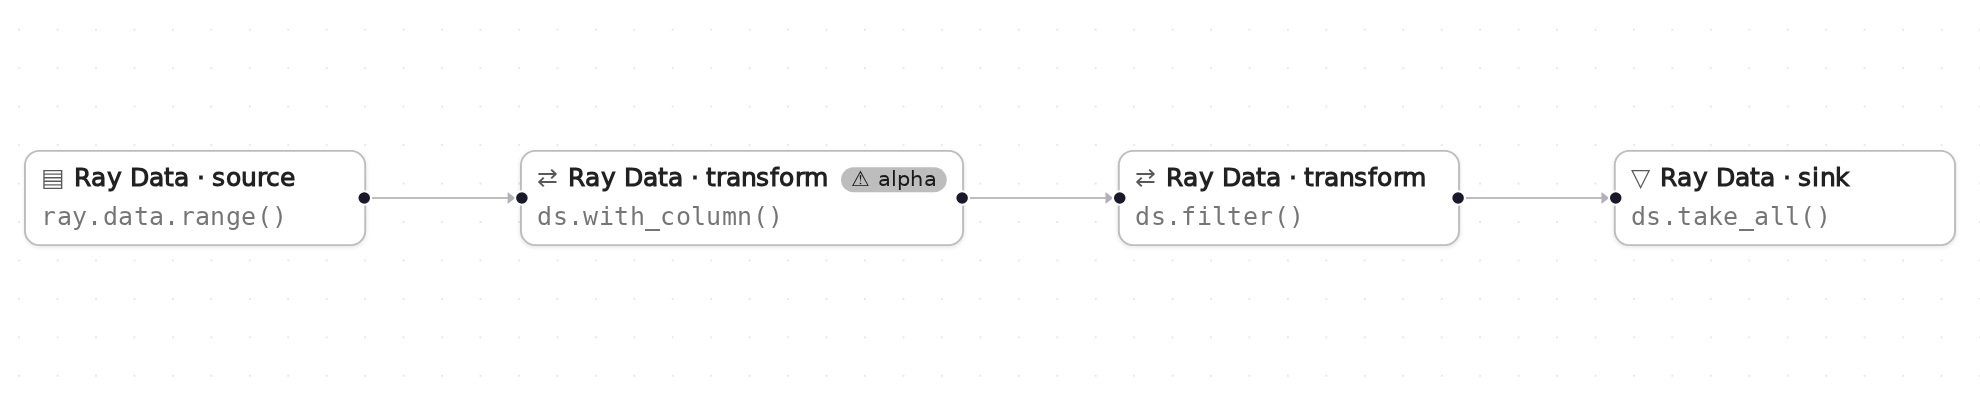

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

This pattern needs no user functions: the column and the filter are expressions.

## Generated code

This is the cell the visual builder generated from the graph above.

In [2]:
# Generated with Eugo's visual Ray builder

import ray
from ray.data.expressions import col, lit

if not ray.is_initialized():
    ray.init()

ds = ray.data.range(10)
ds = ds.with_column("squared", col("id") * col("id"))
ds = ds.filter(expr=col("squared") > lit(20))
rows = ds.take_all()

## Check the result

The cell below checks that the generated code did what the graph describes.

In [3]:
rows = sorted(rows, key=lambda r: r["id"])
assert [r["id"] for r in rows] == [5, 6, 7, 8, 9], rows
assert all(r["squared"] == r["id"] ** 2 for r in rows), rows
print(rows)

[{'id': 5, 'squared': 25}, {'id': 6, 'squared': 36}, {'id': 7, 'squared': 49}, {'id': 8, 'squared': 64}, {'id': 9, 'squared': 81}]


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3–4 and 6–7)

```python
# Generated with Eugo's visual Ray builder
...
import ray
from ray.data.expressions import col, lit
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Source** (node `n1`, line 9)

```python
ds = ray.data.range(10)
```

Ten rows with an id column.

**Transform** (node `n2`, line 10)

```python
ds = ds.with_column("squared", col("id") * col("id"))
```

with_column("squared", col("id") * col("id")) evaluates the expression per block.

**Transform** (node `n3`, line 11)

```python
ds = ds.filter(expr=col("squared") > lit(20))
```

filter(expr=col("squared") > lit(20)) keeps rows where the expression is true.

**Sink** (node `n4`, line 12)

```python
rows = ds.take_all()
```

take_all() collects the remaining rows.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [4]:
ray.shutdown()